# 02 — Analyse des comportements d'achat

**Projet :** Segmentation et score d'appétence d'une base clients retail
**Auteure :** Niya C. Danielle Ouattara

**Objectif :** décrire qui sont les clients et comment ils achètent, avant de construire les segments. Chaque section se termine par un encadré « Constat » à compléter avec les chiffres obtenus.

| Section | Question |
|---|---|
| 1 | Import de la base préparée |
| 2 | Qui sont les clients ? |
| 3 | Qu'achètent-ils ? |
| 4 | Par quels canaux ? |
| 5 | Le revenu explique-t-il la dépense ? |
| 6 | Les familles achètent-elles différemment ? |
| 7 | Qui a répondu à la dernière campagne ? |
| 8 | Synthèse |

Prérequis : avoir exécuté `01_preparation.ipynb`, qui crée `outputs/clients_prepares.csv`.

## 1. Import de la base préparée

In [1]:
import os                                             # os : gestion des dossiers (pour créer le dossier des graphiques)
import pandas as pd                                   # pandas : manipulation de tableaux de données
import matplotlib.pyplot as plt                       # matplotlib : graphiques

pd.set_option("display.max_columns", None)            # afficher toutes les colonnes
os.makedirs("../outputs/figures", exist_ok=True)      # crée le dossier des graphiques s'il n'existe pas encore

df = pd.read_csv("../outputs/clients_prepares.csv")   # base nettoyée et enrichie par le notebook 01
print(df.shape)                                       # on attend 2 232 lignes

Matplotlib is building the font cache; this may take a moment.


(2232, 49)


In [4]:
plt.rcParams["figure.figsize"] = (8, 4)               # taille par défaut des graphiques
plt.rcParams["axes.spines.top"] = False               # retire le cadre du haut, pour des graphiques plus lisibles
plt.rcParams["axes.spines.right"] = False             # retire le cadre de droite
COULEUR = "#1F4E79"                                   # couleur principale utilisée dans tous les graphiques

## 2. Qui sont les clients ?

In [5]:
df[["Age", "Income", "Nb_enfants", "Anciennete_mois"]].describe().round(1)   # âge, revenu, enfants, ancienneté

,Age,Income,Nb_enfants,Anciennete_mois
count,2232.0,2232.0,2232.0,2232.0
mean,45.1,51942.1,1.0,11.6
std,11.7,21422.0,0.8,6.7
min,18.0,1730.0,0.0,0.0
25%,37.0,35434.8,0.0,6.0
50%,44.0,51445.5,1.0,12.0
75%,55.0,68275.8,1.0,17.0
max,74.0,162397.0,3.0,23.0


In [6]:
print(df["Education_fr"].value_counts(normalize=True).round(3))   # normalize=True donne des proportions au lieu d'effectifs
print(df["Situation"].value_counts(normalize=True).round(3))      # part des clients en couple et seuls
print(f"Part de parents : {df['Parent'].mean():.1%}")             # la moyenne d'une colonne 0/1 = proportion de 1

Education_fr
Licence       0.504
Master        0.255
Doctorat      0.216
Secondaire    0.024
Name: proportion, dtype: float64
Situation
En couple    0.646
Seul(e)      0.354
Name: proportion, dtype: float64
Part de parents : 71.6%


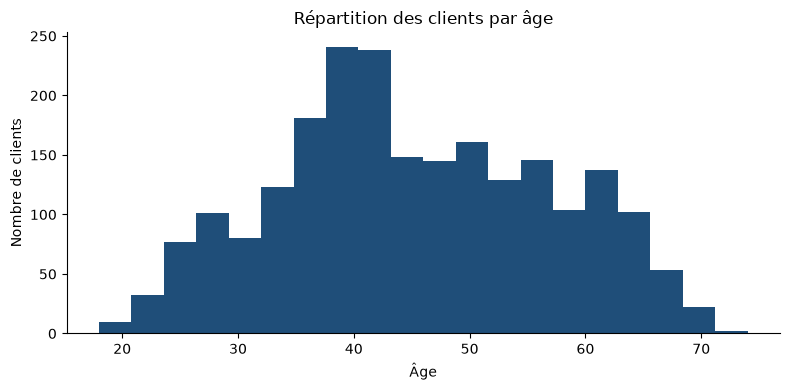

In [7]:
fig, ax = plt.subplots()                                          # crée une zone de dessin
ax.hist(df["Age"], bins=20, color=COULEUR)                        # histogramme de l'âge en 20 intervalles
ax.set_title("Répartition des clients par âge")
ax.set_xlabel("Âge")
ax.set_ylabel("Nombre de clients")
plt.tight_layout()                                                # ajuste les marges
plt.savefig("../outputs/figures/02_age.png", dpi=150)             # enregistre l'image
plt.show()

> **Constat :** la clientèle a en moyenne 45 ans (de 18 à 74 ans), avec un pic entre 35 et 45 ans, et un revenu médian de 51 446 u.m. Elle est diplômée (la moitié a une licence, 47 % un master ou un doctorat), majoritairement en couple (65 %), et 72 % des clients ont au moins un enfant au foyer.

## 3. Qu'achètent-ils ?

In [8]:
categories = {"MntWines": "Vins", "MntMeatProducts": "Viande", "MntGoldProds": "Premium (or)",
              "MntFishProducts": "Poisson", "MntSweetProducts": "Produits sucrés", "MntFruits": "Fruits"}   # libellés en français

depenses = df[list(categories)].sum().rename(categories)          # dépense totale de toute la base, par catégorie
part_depenses = (depenses / depenses.sum()).sort_values()         # part de chaque catégorie dans la dépense totale
print(part_depenses.sort_values(ascending=False).round(3))

Vins               0.502
Viande             0.276
Premium (or)       0.072
Poisson            0.062
Produits sucrés    0.045
Fruits             0.043
dtype: float64


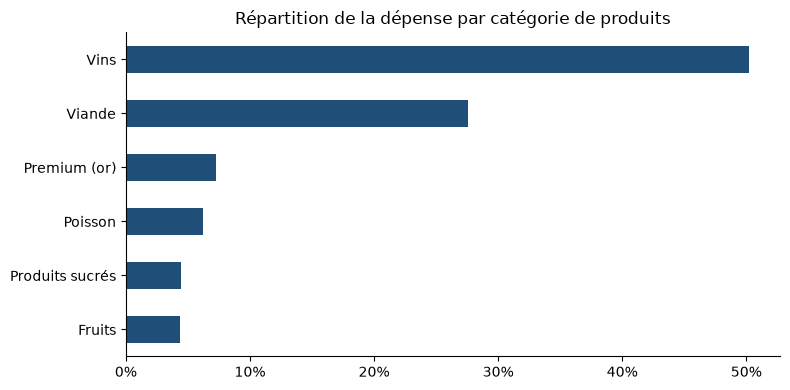

In [9]:
fig, ax = plt.subplots()
part_depenses.plot(kind="barh", ax=ax, color=COULEUR)             # barres horizontales, de la plus petite à la plus grande
ax.set_title("Répartition de la dépense par catégorie de produits")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))   # axe en pourcentage
plt.tight_layout()
plt.savefig("../outputs/figures/02_categories.png", dpi=150)
plt.show()

In [10]:
part_cumulee = (df["Depense_totale"].sort_values(ascending=False).cumsum()   # dépense cumulée, des plus gros clients aux plus petits
                / df["Depense_totale"].sum())                                # divisée par le total : de 0 à 1
part_clients_50 = (part_cumulee <= 0.5).mean()                               # part des clients qui font la moitié du chiffre d'affaires
print(f"{part_clients_50:.1%} des clients réalisent 50 % de la dépense totale")

18.8% des clients réalisent 50 % de la dépense totale


> **Constat :** les vins (50 %) et la viande (28 %) représentent à eux seuls 78 % de la dépense ; les autres catégories pèsent chacune moins de 8 %. La dépense est très concentrée : 18,8 % des clients réalisent la moitié du chiffre d'affaires.

## 4. Par quels canaux ?

In [11]:
canaux = {"NumStorePurchases": "Magasin", "NumWebPurchases": "Web", "NumCatalogPurchases": "Catalogue"}
achats = df[list(canaux)].sum().rename(canaux)                    # nombre total d'achats par canal
print((achats / achats.sum()).round(3))                           # part de chaque canal dans les achats
print(f"Achats en promotion : {df['NumDealsPurchases'].sum() / achats.sum():.1%} des achats")
print(f"Visites web par mois (médiane) : {df['NumWebVisitsMonth'].median():.0f}")

Magasin      0.462
Web          0.326
Catalogue    0.212
dtype: float64
Achats en promotion : 18.5% des achats
Visites web par mois (médiane) : 6


In [12]:
canal_principal = df[["Part_magasin", "Part_web", "Part_catalogue"]].idxmax(axis=1)   # pour chaque client, le canal le plus utilisé
canal_principal = canal_principal.str.replace("Part_", "").str.capitalize()           # « Part_web » devient « Web »
print(canal_principal.value_counts(normalize=True).round(3))                          # répartition des clients par canal principal

Magasin      0.789
Web          0.150
Catalogue    0.060
Name: proportion, dtype: float64


> **Constat :** le magasin concentre 46 % des achats, devant le web (33 %) et le catalogue (21 %). Pour 79 % des clients, le magasin est le canal principal ; le web ne l'est que pour 15 % d'entre eux, alors qu'ils visitent le site 6 fois par mois en médiane. Les achats en promotion représentent 18,5 % des achats.

## 5. Le revenu explique-t-il la dépense ?

In [13]:
correlation = df["Income"].corr(df["Depense_totale"])             # corrélation de Pearson entre -1 et 1
print(f"Corrélation revenu / dépense : {correlation:.2f}")

Corrélation revenu / dépense : 0.79


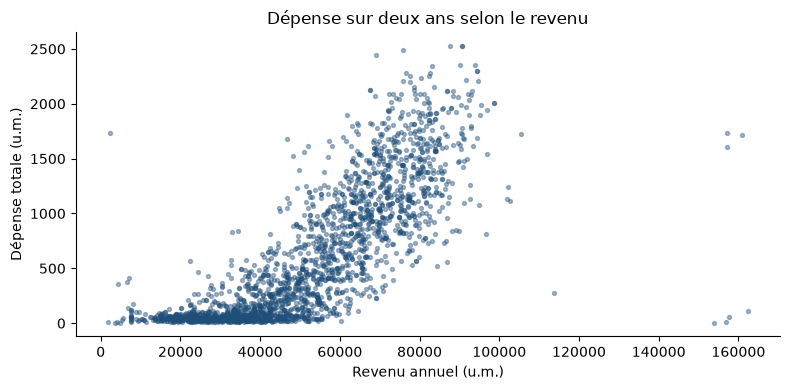

In [14]:
fig, ax = plt.subplots()
ax.scatter(df["Income"], df["Depense_totale"], s=8, alpha=0.4, color=COULEUR)   # un point par client ; alpha rend les points transparents
ax.set_title("Dépense sur deux ans selon le revenu")
ax.set_xlabel("Revenu annuel (u.m.)")
ax.set_ylabel("Dépense totale (u.m.)")
plt.tight_layout()
plt.savefig("../outputs/figures/02_revenu_depense.png", dpi=150)
plt.show()

In [15]:
df["Tranche_revenu"] = pd.qcut(df["Income"], 4,                   # 4 groupes de même effectif (quartiles)
                               labels=["1. Revenus modestes", "2. Revenus moyens",
                                       "3. Revenus aisés", "4. Hauts revenus"])
(df.groupby("Tranche_revenu", observed=True)                      # un groupe par tranche
   [["Depense_totale", "Panier_moyen", "Part_promo", "Part_web", "NumWebVisitsMonth"]]
   .median()                                                      # médiane : moins sensible aux valeurs extrêmes que la moyenne
   .round(2))

,Depense_totale,Panier_moyen,Part_promo,Part_web,NumWebVisitsMonth
Tranche_revenu,,,,,
1. Revenus modestes,52.0,10.45,0.33,0.33,7.0
2. Revenus moyens,151.5,20.78,0.33,0.38,7.0
3. Revenus aisés,730.5,37.94,0.17,0.33,5.0
4. Hauts revenus,1366.0,70.33,0.06,0.27,2.0


> **Constat :** la corrélation revenu / dépense est forte (0,79). Les hauts revenus dépensent 26 fois plus que les revenus modestes (1 366 u.m. contre 52 en médiane), avec un panier moyen 7 fois plus élevé. Les revenus modestes et moyens achètent un tiers de leurs produits en promotion, contre 6 % pour les hauts revenus, et visitent le site 7 fois par mois, contre 2. Une dizaine de clients déclarent plus de 150 000 u.m. de revenu pour une dépense quasi nulle : ce profil incohérent sera surveillé lors de la segmentation.

## 6. Les familles achètent-elles différemment ?

In [16]:
(df.groupby("Nb_enfants")                                         # un groupe par nombre d'enfants au foyer
   .agg(nb_clients=("ID", "count"),                               # effectif du groupe
        depense_mediane=("Depense_totale", "median"),             # dépense médiane
        part_promo=("Part_promo", "median"),                      # part médiane des achats en promotion
        taux_reponse=("Response", "mean"))                        # taux de réponse à la dernière campagne
   .round(2))

,nb_clients,depense_mediane,part_promo,taux_reponse
Nb_enfants,,,,
0,635,1189.0,0.06,0.26
1,1123,306.0,0.24,0.10
2,421,93.0,0.44,0.11
3,53,88.0,0.43,0.04


> **Constat :** les foyers sans enfant dépensent 13 fois plus que les foyers avec deux enfants ou plus (1 189 u.m. contre moins de 100 en médiane), achètent très peu en promotion (6 % contre plus de 40 %) et répondent deux fois plus aux campagnes (26 % contre 11 %, et 4 % pour les familles de trois enfants).

## 7. Qui a répondu à la dernière campagne ?

In [17]:
def taux_reponse(colonne):                                        # petite fonction réutilisable
    return (df.groupby(colonne, observed=True)["Response"]        # regroupe par valeur de la colonne
              .agg(nb_clients="count", taux_reponse="mean")       # effectif et taux de réponse
              .round(3))

In [18]:
taux_reponse("Tranche_revenu")                                    # réponse selon le revenu

,nb_clients,taux_reponse
Tranche_revenu,,
1. Revenus modestes,558,0.104
2. Revenus moyens,558,0.124
3. Revenus aisés,558,0.100
4. Hauts revenus,558,0.267


In [19]:
taux_reponse("Nb_campagnes_acceptees")                            # réponse selon le nombre de campagnes déjà acceptées

,nb_clients,taux_reponse
Nb_campagnes_acceptees,,
0,1771,0.082
1,324,0.312
2,82,0.500
3,44,0.795
4,11,0.909


In [20]:
df["Recence_tranche"] = pd.cut(df["Recency"], bins=[-1, 30, 60, 100],   # jours depuis le dernier achat, en 3 tranches
                               labels=["0-30 jours", "31-60 jours", "61-99 jours"])
taux_reponse("Recence_tranche")                                   # réponse selon la récence du dernier achat

,nb_clients,taux_reponse
Recence_tranche,,
0-30 jours,720,0.239
31-60 jours,651,0.135
61-99 jours,861,0.084


In [21]:
taux_reponse("Situation")                                         # réponse selon la situation familiale

,nb_clients,taux_reponse
Situation,,
En couple,1442,0.11
Seul(e),790,0.22


> **Constat :** les campagnes passées sont le signal le plus fort. Un client qui en a accepté une répond à 31 %, contre 8 % pour un client qui n'en a accepté aucune, soit près de 4 fois plus ; ce taux monte à 50 % après deux campagnes et à 80 % après trois. La récence compte aussi : 24 % de réponse pour un achat dans les 30 derniers jours, contre 8 % au-delà de 60 jours. Les hauts revenus (27 %) et les personnes seules (22 % contre 11 % en couple) répondent également davantage.

## 8. Synthèse et suites

1. **Une dépense très concentrée** : 18,8 % des clients réalisent la moitié du chiffre d'affaires, et les vins et la viande pèsent 78 % de la dépense.
2. **Un parcours d'achat ancré en magasin** : 79 % des clients achètent d'abord en magasin ; le site est très visité mais peu utilisé pour acheter, surtout par les revenus modestes.
3. **Deux clientèles opposées** : d'un côté des foyers aisés, sans enfant, qui dépensent beaucoup, achètent peu en promotion et répondent aux campagnes ; de l'autre des familles aux revenus modestes, sensibles aux promotions, qui dépensent peu et répondent rarement.
4. **Des signaux de réponse très nets** : l'historique de campagnes acceptées et la récence du dernier achat distinguent fortement les répondants des autres. Ce sont les premiers candidats du score d'appétence.

**Conséquences pour la segmentation (notebook 03) :**
- variables retenues : dépense totale, nombre d'achats, revenu, parts par canal, part des achats en promotion, nombre d'enfants ;
- le panier moyen présente des valeurs extrêmes (jusqu'à 1 679 u.m. pour une médiane de 29,6) : il sera plafonné ou écarté ;
- les clients déclarant plus de 150 000 u.m. de revenu pour une dépense quasi nulle seront examinés avant la segmentation ;
- les variables seront standardisées, car elles ne sont pas exprimées dans les mêmes unités.

**Conséquences pour le score (notebook 04) :** la récence et le nombre de campagnes déjà acceptées sont des candidats prioritaires.